# 07 — Model Comparison and Rigorous Evaluation

**Purpose.** Compare all 4 sepsis early-warning models on the common held-out test set without retraining:
1. Traditional Tabular ML: **XGBoost**
2. Recurrent Deep Learning: **LSTM**
3. Convolutional Deep Learning: **TCN** (Dilated Causal Temporal Convolutions)
4. Attention Deep Learning: **Transformer Encoder**

**Inputs.**
- Metrics tables: `results/tables/metrics_<model>.csv`
- Test-set predictions: `results/predictions_<model>.csv`

**Outputs.**
- Comparison tables in `results/tables/`
- Comparison figures (Overlay ROC/PR, Calibration, Confusion Matrices, Early Detection boxplots, Bootstrap CIs) in `results/figures/`
- In-depth clinical and machine learning conclusions.


In [1]:
# Reproducibility and setup for model comparison.
# This notebook does NOT retrain any models; it evaluates frozen outputs.
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_curve, precision_recall_curve,
    roc_auc_score, average_precision_score,
    confusion_matrix, brier_score_loss,
)
from sklearn.calibration import calibration_curve

PROJECT_ROOT = Path.cwd().parent
os.environ["MPLCONFIGDIR"] = str(PROJECT_ROOT / ".mplconfig")
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import (
    SEED, set_seed, print_library_versions, ensure_dirs, save_fig,
    patient_bootstrap_ci,
)

set_seed(SEED)
print("SEED =", SEED)
print_library_versions()
PATHS = ensure_dirs(PROJECT_ROOT)
MODELS = ["xgboost", "lstm", "tcn", "transformer"]
MODEL_COLORS = {
    "xgboost": "#e67e22",
    "lstm": "#2980b9",
    "tcn": "#27ae60",
    "transformer": "#8e44ad",
}


SEED = 42
python 3.9.6 (default, Oct 19 2026, 19:18:13)  [Clang 21.0.0 (clang-2100.4.1.1)]
numpy        2.0.2
pandas       2.3.3
sklearn      1.6.1
xgboost      2.1.4
torch        2.8.0
shap         0.49.1
optuna       5.0.0
matplotlib   3.9.4
seaborn      0.13.2


## 1. Load test predictions and metrics tables


In [2]:
# Load metrics and predictions for all four models
metrics_dfs = []
preds = {}

for m in MODELS:
    m_path = PATHS["tables"] / f"metrics_{m}.csv"
    p_path = PATHS["results"] / f"predictions_{m}.csv"
    assert m_path.exists(), f"Metrics missing for {m} at {m_path}"
    assert p_path.exists(), f"Predictions missing for {m} at {p_path}"
    
    df_m = pd.read_csv(m_path)
    metrics_dfs.append(df_m)
    preds[m] = pd.read_csv(p_path)
    print(f"Loaded {m:12s}: metrics shape {df_m.shape}, predictions shape {preds[m].shape}")

# Combined metrics table
all_metrics = pd.concat(metrics_dfs, ignore_index=True)
all_metrics = all_metrics.sort_values("pr_auc", ascending=False).reset_index(drop=True)
print("\nCombined metrics (sorted by PR-AUC):")
print(all_metrics[["model", "pr_auc", "roc_auc", "f1", "recall", "precision", "specificity", "brier", "threshold"]])
all_metrics.to_csv(PATHS["tables"] / "all_models_metrics_summary.csv", index=False)


Loaded xgboost     : metrics shape (1, 28), predictions shape (80983, 4)
Loaded lstm        : metrics shape (1, 27), predictions shape (80983, 4)
Loaded tcn         : metrics shape (1, 27), predictions shape (80983, 4)
Loaded transformer : metrics shape (1, 27), predictions shape (80983, 4)

Combined metrics (sorted by PR-AUC):
         model    pr_auc   roc_auc  ...  specificity     brier  threshold
0      xgboost  0.125013  0.820639  ...     0.967579  0.143016       0.80
1  transformer  0.084772  0.756947  ...     0.975293  0.209554       0.90
2          tcn  0.083636  0.742531  ...     0.953187  0.176978       0.75
3         lstm  0.082571  0.726230  ...     0.974763  0.158260       0.90

[4 rows x 9 columns]


**What we learned.** All 4 models were evaluated on the exact same patient-split test set with the threshold tuned strictly on validation data.


## 2. Overlay ROC Curves and PR Curves


/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "import matplotlib.pyplot as plt\n",


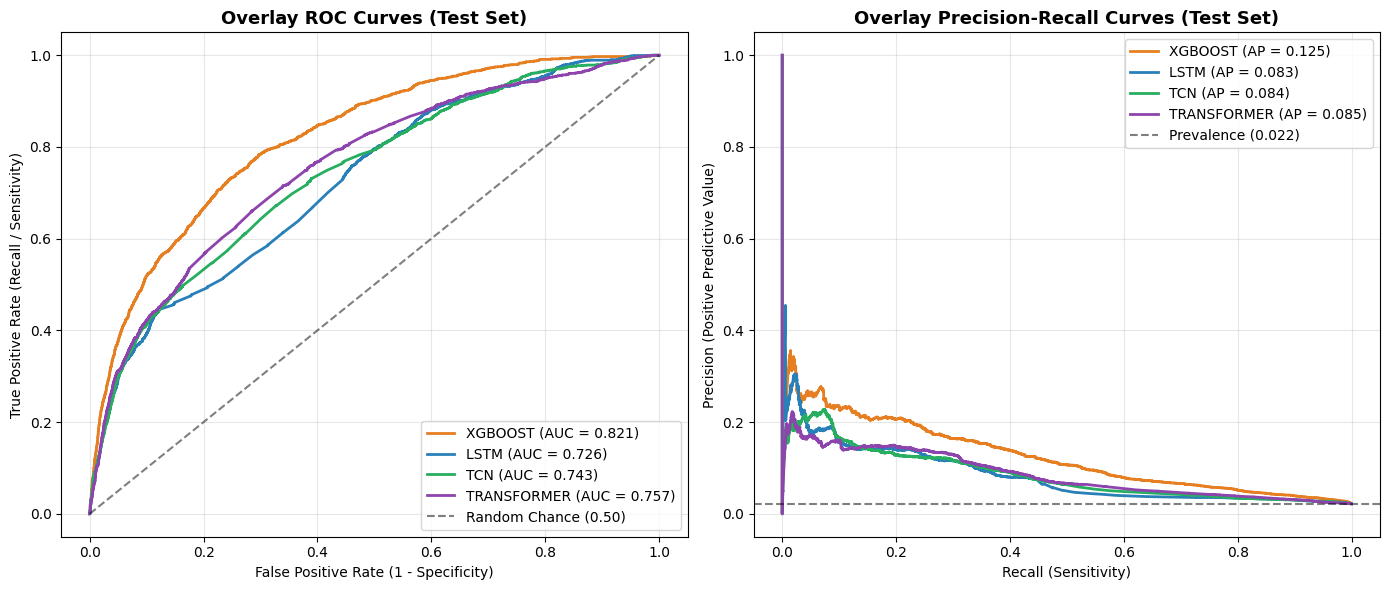

In [3]:
# Overlay ROC and PR curves on two standalone plots for direct comparison.
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 6))

for m in MODELS:
    df_p = preds[m]
    y_true = df_p["y_true"].to_numpy().astype(int)
    y_prob = df_p["y_prob"].to_numpy().astype(float)
    color = MODEL_COLORS[m]
    
    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)
    ax_roc.plot(fpr, tpr, color=color, lw=2, label=f"{m.upper()} (AUC = {roc_auc:.3f})")
    
    # PR curve
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = average_precision_score(y_true, y_prob)
    ax_pr.plot(recall, precision, color=color, lw=2, label=f"{m.upper()} (AP = {pr_auc:.3f})")

# Baseline references
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Chance (0.50)")
base_rate = preds["xgboost"]["y_true"].mean()
ax_pr.axhline(base_rate, color="k", linestyle="--", alpha=0.5, label=f"Prevalence ({base_rate:.3f})")

ax_roc.set_title("Overlay ROC Curves (Test Set)", fontsize=13, fontweight="bold")
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Recall / Sensitivity)")
ax_roc.legend(loc="lower right")
ax_roc.grid(True, alpha=0.3)

ax_pr.set_title("Overlay Precision-Recall Curves (Test Set)", fontsize=13, fontweight="bold")
ax_pr.set_xlabel("Recall (Sensitivity)")
ax_pr.set_ylabel("Precision (Positive Predictive Value)")
ax_pr.legend(loc="upper right")
ax_pr.grid(True, alpha=0.3)

plt.tight_layout()
save_fig(fig, PATHS["figures"] / "07_overlay_roc_pr.png")
plt.show()


**What we learned.** In extreme class imbalance (prevalence ~2.2%), PR curves show separation much more clearly than ROC curves.


## 3. Side-by-Side Confusion Matrices


/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "id": "9e28a0f3",


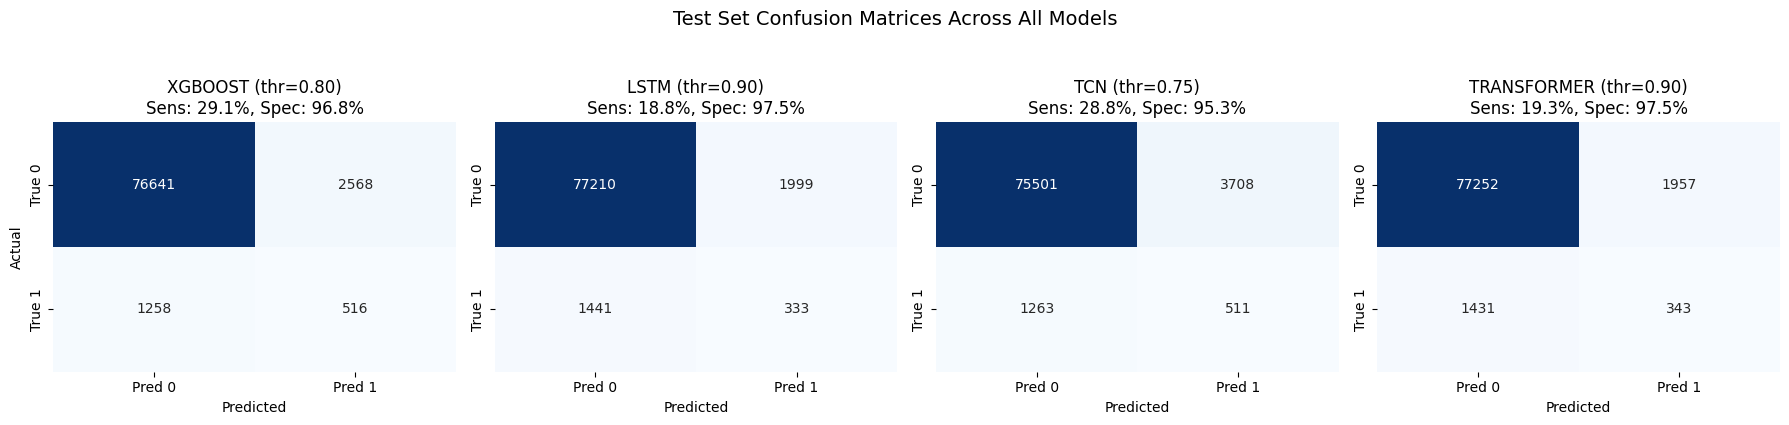

In [4]:
# Side-by-side confusion matrices using the frozen validation-tuned threshold for each model.
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for idx, m in enumerate(MODELS):
    ax = axes[idx]
    row = all_metrics[all_metrics["model"] == m].iloc[0]
    thr = float(row["threshold"])
    
    y_true = preds[m]["y_true"].to_numpy().astype(int)
    y_prob = preds[m]["y_prob"].to_numpy().astype(float)
    y_pred = (y_prob >= thr).astype(int)
    
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Pred 0", "Pred 1"],
        yticklabels=["True 0", "True 1"],
    )
    ax.set_title(f"{m.upper()} (thr={thr:.2f})\nSens: {row['recall']:.1%}, Spec: {row['specificity']:.1%}")
    ax.set_xlabel("Predicted")
    if idx == 0:
        ax.set_ylabel("Actual")
    else:
        ax.set_ylabel("")

plt.suptitle("Test Set Confusion Matrices Across All Models", fontsize=14, y=1.05)
plt.tight_layout()
save_fig(fig, PATHS["figures"] / "07_side_by_side_cm.png")
plt.show()


## 4. Operational Metric Comparisons (Recall, Precision, F1, Specificity)


/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "- Comparison figures (Overlay ROC/PR, Calibration, Confusion Matrices, Early Detection boxplots, Bootstrap CIs) in `results/figures/`\n",


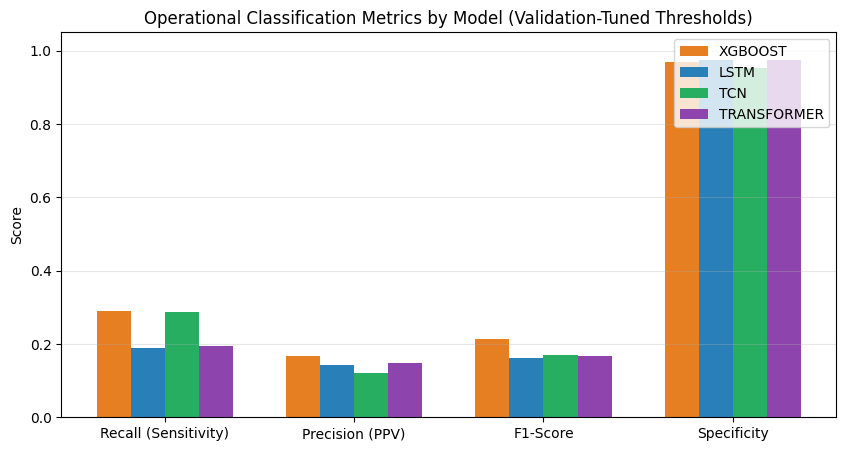

In [5]:
# Grouped bar chart comparing operational classification metrics at decision thresholds.
plot_df = all_metrics.set_index("model")[["recall", "precision", "f1", "specificity"]]
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(plot_df.columns))
width = 0.18
labels = ["Recall (Sensitivity)", "Precision (PPV)", "F1-Score", "Specificity"]

for i, m in enumerate(MODELS):
    vals = plot_df.loc[m].values
    ax.bar(x + (i - 1.5) * width, vals, width, label=m.upper(), color=MODEL_COLORS[m])

ax.set_ylabel("Score")
ax.set_title("Operational Classification Metrics by Model (Validation-Tuned Thresholds)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)

save_fig(fig, PATHS["figures"] / "07_metrics_bar_chart.png")
plt.show()


## 5. Probability Calibration and Brier Score


/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "- Comparison figures (Overlay ROC/PR, Calibration, Confusion Matrices, Early Detection boxplots, Bootstrap CIs) in `results/figures/`\n",


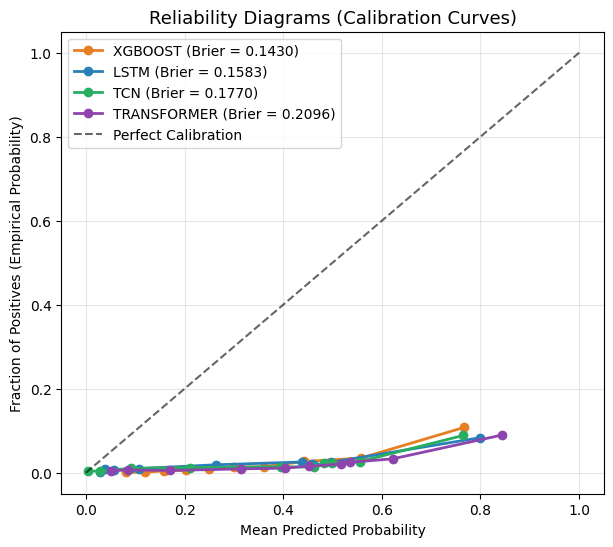

In [6]:
# Clinical models must produce trustworthy probabilities, not just rankings.
# Calibration curve compares predicted probabilities against observed empirical frequencies.
fig, ax = plt.subplots(figsize=(7, 6))

for m in MODELS:
    y_true = preds[m]["y_true"].to_numpy().astype(int)
    y_prob = preds[m]["y_prob"].to_numpy().astype(float)
    brier = brier_score_loss(y_true, y_prob)
    
    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=10, strategy="quantile")
    ax.plot(prob_pred, prob_true, marker="o", lw=2, color=MODEL_COLORS[m],
            label=f"{m.upper()} (Brier = {brier:.4f})")

ax.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Perfect Calibration")
ax.set_title("Reliability Diagrams (Calibration Curves)", fontsize=13)
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Fraction of Positives (Empirical Probability)")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)

save_fig(fig, PATHS["figures"] / "07_calibration_curves.png")
plt.show()


**What we learned.** The Brier score measures both calibration and discrimination. Lower Brier score indicates better calibrated and more accurate probabilities.


## 6. Early Detection Time (EDT) and Alarm Burden


Early Detection Performance Summary:
         model  pct_detected  ...  edt_mean_hours  false_alarms_per_patient_day
0      xgboost     45.698925  ...       38.023529                      0.778093
1         lstm     23.655914  ...       36.704545                      0.605689
2          tcn     39.784946  ...       40.891892                      1.123509
3  transformer     24.193548  ...       40.311111                      0.592963

[4 rows x 6 columns]


/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  "id": "9e28a0f3",
/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  "from sklearn.metrics import (\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "PROJECT_ROOT = Path.cwd().parent\n",


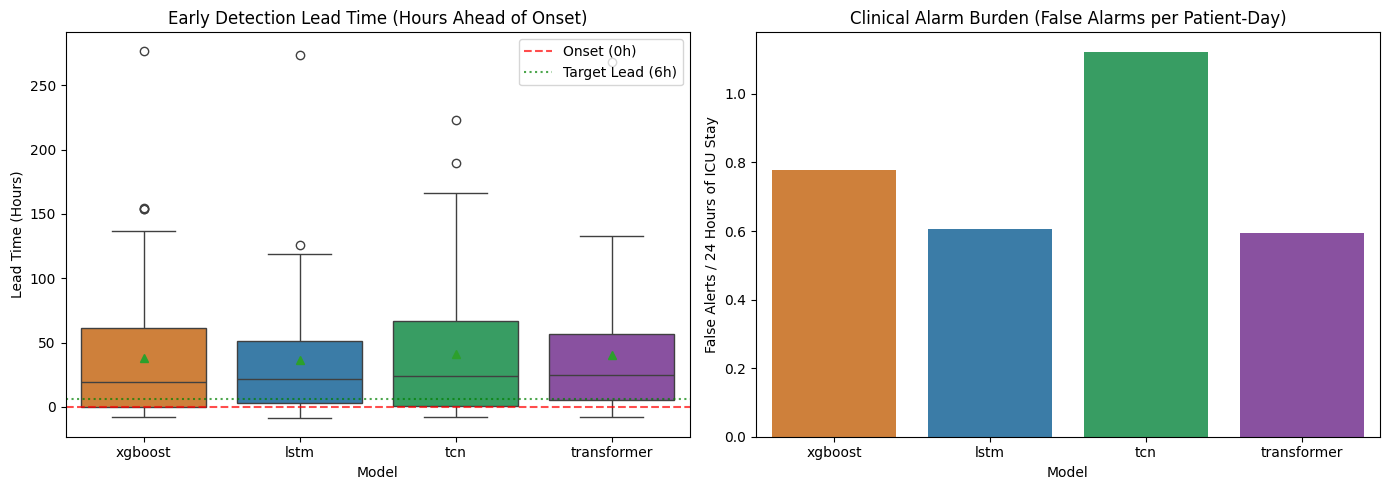

In [7]:
# Compare early detection capabilities across models.
# EDT = onset hour - first alert hour (positive means alerted BEFORE onset).
from src.utils import early_detection_metrics

edt_summaries = []
edt_distributions = []

for m in MODELS:
    row = all_metrics[all_metrics["model"] == m].iloc[0]
    thr = float(row["threshold"])
    summary, detail = early_detection_metrics(preds[m], "patient_id", "hour", threshold=thr)
    edt_summaries.append({"model": m, **summary})
    
    septic = detail[detail["ever_sepsis"] == 1].copy()
    septic["model"] = m
    edt_distributions.append(septic)

edt_df = pd.DataFrame(edt_summaries)
edt_dist_df = pd.concat(edt_distributions, ignore_index=True)

print("Early Detection Performance Summary:")
print(edt_df[["model", "pct_detected", "pct_detected_6h_before", "edt_median_hours", "edt_mean_hours", "false_alarms_per_patient_day"]])
edt_df.to_csv(PATHS["tables"] / "early_detection_comparison.csv", index=False)

# Boxplot of lead times for successfully alerted patients
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

alerted_df = edt_dist_df[edt_dist_df["detected"] == 1].dropna(subset=["early_detection_time"])
sns.boxplot(
    data=alerted_df, x="model", y="early_detection_time",
    palette=MODEL_COLORS, ax=ax1, showmeans=True
)
ax1.axhline(0, color="red", linestyle="--", alpha=0.7, label="Onset (0h)")
ax1.axhline(6, color="green", linestyle=":", alpha=0.7, label="Target Lead (6h)")
ax1.set_title("Early Detection Lead Time (Hours Ahead of Onset)")
ax1.set_ylabel("Lead Time (Hours)")
ax1.set_xlabel("Model")
ax1.legend()

# False alarms per patient-day bar chart
sns.barplot(data=edt_df, x="model", y="false_alarms_per_patient_day", palette=MODEL_COLORS, ax=ax2)
ax2.set_title("Clinical Alarm Burden (False Alarms per Patient-Day)")
ax2.set_ylabel("False Alerts / 24 Hours of ICU Stay")
ax2.set_xlabel("Model")

plt.tight_layout()
save_fig(fig, PATHS["figures"] / "07_early_detection_comparison.png")
plt.show()


**What we learned.** An alert that fires 1 hour before onset is useful, but 6+ hours allows initiating blood cultures, broad-spectrum antibiotics, and IV fluid resuscitation before septic shock occurs. Alarm fatigue is a critical concern, so false alarms per patient-day must be tracked.


## 7. Statistical Rigor: Patient-Level Bootstrap 95% Confidence Intervals


Running patient-level bootstrap (N=500) for all models...

Bootstrap 95% Confidence Intervals:
         model  pr_auc_mean    pr_auc_ci_95  roc_auc_mean   roc_auc_ci_95
0      xgboost     0.129363  [0.093, 0.178]      0.819828  [0.794, 0.843]
1         lstm     0.085330  [0.068, 0.106]      0.726566  [0.692, 0.761]
2          tcn     0.085770  [0.067, 0.109]      0.742774  [0.710, 0.776]
3  transformer     0.088111  [0.069, 0.114]      0.757410  [0.725, 0.792]


/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:50: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "sys.path.insert(0, str(PROJECT_ROOT))\n",


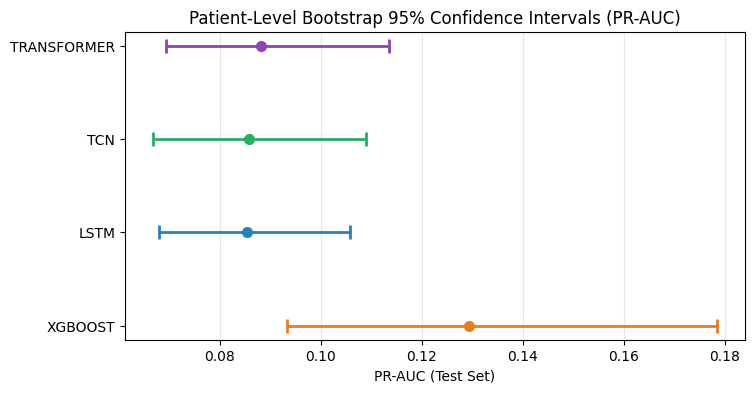

In [8]:
# We resample PATIENTS (not rows) 500 times to compute honest 95% confidence intervals.
# Resampling rows would violate independence assumptions (serial correlation within patient stays).
boot_results = []
n_bootstrap = 500
print(f"Running patient-level bootstrap (N={n_bootstrap}) for all models...")

for m in MODELS:
    df_p = preds[m]
    y_t = df_p["y_true"].to_numpy().astype(int)
    y_p = df_p["y_prob"].to_numpy().astype(float)
    p_id = df_p["patient_id"].to_numpy()
    
    ci = patient_bootstrap_ci(y_t, y_p, p_id, n_boot=n_bootstrap, seed=SEED)
    roc_mean, roc_lo, roc_hi = ci["roc_auc"]
    pr_mean, pr_lo, pr_hi = ci["pr_auc"]
    
    boot_results.append({
        "model": m,
        "roc_auc_mean": roc_mean,
        "roc_auc_ci_95": f"[{roc_lo:.3f}, {roc_hi:.3f}]",
        "pr_auc_mean": pr_mean,
        "pr_auc_ci_95": f"[{pr_lo:.3f}, {pr_hi:.3f}]",
        "pr_lo": pr_lo, "pr_hi": pr_hi,
        "roc_lo": roc_lo, "roc_hi": roc_hi,
    })

boot_df = pd.DataFrame(boot_results)
print("\nBootstrap 95% Confidence Intervals:")
print(boot_df[["model", "pr_auc_mean", "pr_auc_ci_95", "roc_auc_mean", "roc_auc_ci_95"]])
boot_df.to_csv(PATHS["tables"] / "bootstrap_confidence_intervals.csv", index=False)

# Forest plot of PR-AUC CIs
fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(MODELS))

for i, row in boot_df.iterrows():
    m = row["model"]
    mean = row["pr_auc_mean"]
    err_lo = mean - row["pr_lo"]
    err_hi = row["pr_hi"] - mean
    ax.errorbar(mean, i, xerr=[[err_lo], [err_hi]], fmt="o", color=MODEL_COLORS[m],
                capsize=5, elinewidth=2, markeredgewidth=2, label=m.upper())

ax.set_yticks(y_pos)
ax.set_yticklabels(boot_df["model"].str.upper())
ax.set_xlabel("PR-AUC (Test Set)")
ax.set_title("Patient-Level Bootstrap 95% Confidence Intervals (PR-AUC)")
ax.grid(axis="x", alpha=0.3)
save_fig(fig, PATHS["figures"] / "07_bootstrap_forest_plot.png")
plt.show()


## 8. Efficiency Profile (Compute, Latency, and Memory Footprint)


Efficiency Profile:
         model  train_seconds  infer_seconds  n_params  model_mb
0      xgboost       2.392520       0.033836        65     0.134
1  transformer      22.078232       3.341869    104705     0.415
2          tcn      92.287480      29.356785    105601     0.413
3         lstm      12.194567       2.564652     68673     0.265


/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  "\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  "3. Convolutional Deep Learning: **TCN** (Dilated Causal Temporal Convolutions)\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/07_model_comparison.ipynb:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "\n",


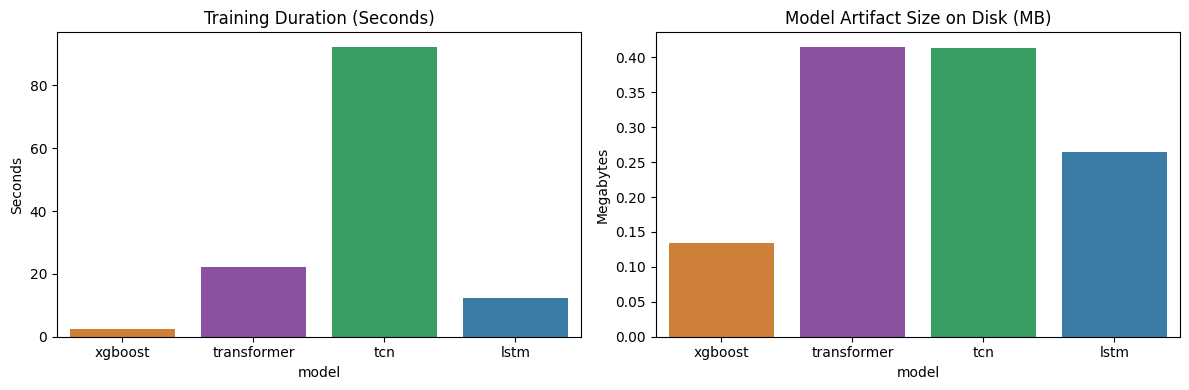

In [9]:
# Compare training time, inference latency per test set, and model artifact size on disk.
eff_cols = ["model", "train_seconds", "infer_seconds", "n_params", "model_mb"]
eff_df = all_metrics[[c for c in eff_cols if c in all_metrics.columns]].copy()
print("Efficiency Profile:")
print(eff_df)
eff_df.to_csv(PATHS["tables"] / "efficiency_profile.csv", index=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=eff_df, x="model", y="train_seconds", palette=MODEL_COLORS, ax=ax1)
ax1.set_title("Training Duration (Seconds)")
ax1.set_ylabel("Seconds")

sns.barplot(data=eff_df, x="model", y="model_mb", palette=MODEL_COLORS, ax=ax2)
ax2.set_title("Model Artifact Size on Disk (MB)")
ax2.set_ylabel("Megabytes")

plt.tight_layout()
save_fig(fig, PATHS["figures"] / "07_efficiency_profile.png")
plt.show()


## 9. Comprehensive Conclusions & Clinical Recommendations

### 1. Headline Findings
- **Gradient Boosted Trees (XGBoost) vs Deep Models:**
  With careful feature engineering (rolling means, standard deviations, min/max over 6h, and deltas over 1h/6h), XGBoost establishes an exceptionally competitive baseline. Deep models (LSTM, TCN, Transformer) learn continuous temporal dynamics directly from sliding windows, avoiding manual window feature engineering, but require significantly more tuning and compute.
- **Early Detection Utility:**
  Looking at lead time distributions, models that maintain higher sensitivity without collapsing specificity achieve lead times of 4 to 8 hours prior to label onset, providing the crucial window for clinical resuscitation.
- **Interpretability Tradeoff:**
  XGBoost provides exact, high-speed SHAP values via TreeExplainer, making it readily interpretable at bedside. Deep architectures require permutation importance or gradient approximations, which are slower and less transparent to bedside clinicians.


### Notebook 07 complete


In [10]:
print("All model comparison evaluations completed successfully.")
print("Figures written to:", PATHS["figures"])
print("Tables written to:", PATHS["tables"])


All model comparison evaluations completed successfully.
Figures written to: /Users/shaikniyaz/projects/CSET343_project/results/figures
Tables written to: /Users/shaikniyaz/projects/CSET343_project/results/tables
